# Lab Assignment 3 - Scientific Computing Lab

## Submitted by - Naman Jain, SC26M013

## Blasius Solution
This report contains how to solve the Blasius Equation for a steady, incompressible flow of a uniform stream $U$ over a flat plate after the similarity transformation $\eta = y\sqrt{U_{\infty}/\nu x}$, $u/U_{\infty} = f'(\eta)$. The main equation to solve is:

$$ f''' + \frac{1}{2}ff'' = 0,
\qquad
0 < \eta < \infty$$

To solve this, we have boundary conditions as:

$$ f(0) = 0, \qquad f'(0) = 0,\qquad f'(\infty) \rightarrow 1$$
where $f(0) = 0, f'(0) = 0$ are no slip conditions at wall. 

### Idea of Implementation. 
1. Write the Blasius Equation as 3 first-order equations of the form: $Y' = G(Y)$ where $Y = (f, f', f'')^T$.
2. Use RK3 and RK4 numerical methods to solve the system of equations of first-order form with a fixed time step.
3. Solve the system via **shooting method** i.e. two conditions are given at $\eta = 0$ and one at $\eta = \infty$. Assume the third conditions at $\eta = 0$ so that BVP is converted into a IVP.
$$ f(0) = 0, \qquad f'(0) = 0, \qquad f''(0) = s$$
where $s$ is the shooting parameter, the assumed value.
4. Define the residual error:
$$F(s;\eta_{\infty}) = f'(\eta_{\infty};s) - 1$$
5. Solve this root finding method using bisection method to iterate the value of $s$ so that we reach the correct initial conditions.
6. With RK3, RK4, compute $s$ for $\Delta\eta = 0.4, 0.2, 0.1, 0.05, 0.025$. Confirm the expected order of accuracy from a log–log plot.
7. Plot $f, f', f''$ against $\eta$
8. Check: the converged value should agree with $f''(0) = 0.332$ to 3 digits. 

### Convert Third-Order to First-Order:
$$ 2f''' + ff'' = 0$$
Assume parameters $u_{1}, u_{2}, u_{3}$ such that:
$$u_{1} = f, \qquad u_{2} = f',\qquad u_{3} = f''$$
$$u_{1}' = f', \qquad u_{2}' = f'', \qquad u_{3}' = f'''$$
Putting $u_{3}' = f'''$ in Blasius eqn, we get:
$$ u_{3}' = f''' = \frac{-u_{1}u_{3}}{2}$$
Forming this whole into a matrix form, we get:
$$\begin{bmatrix}
u_{1}'\\
u_{2}'\\
u_{3}'
\end{bmatrix} = 
\begin{bmatrix}
0 & 1 & 0\\
0 & 0 & 1\\
0 & 0 & \frac{-u_{1}}{2}
\end{bmatrix}
\begin{bmatrix}
u_{1}\\
u_{2}\\
u_{3}
\end{bmatrix}$$ 
This is form the form: $Y' = G(Y)$

**RK3 Scheme**
$$\begin{aligned}
K_1 &= hF(Y_n)\\
K_2 &= hF\left(Y_n+\frac{K_1}{2}\right)\\
K_3 &= hF\left(Y_n-K_1+2K_2\right)
\end{aligned}$$
updation: 
$$
Y_{n+1}=Y_n+\frac{1}{6}(K_1+4K_2+K_3)
$$

Shooting Parameter s:  0.3320565324384775
f'(eta):  1.0


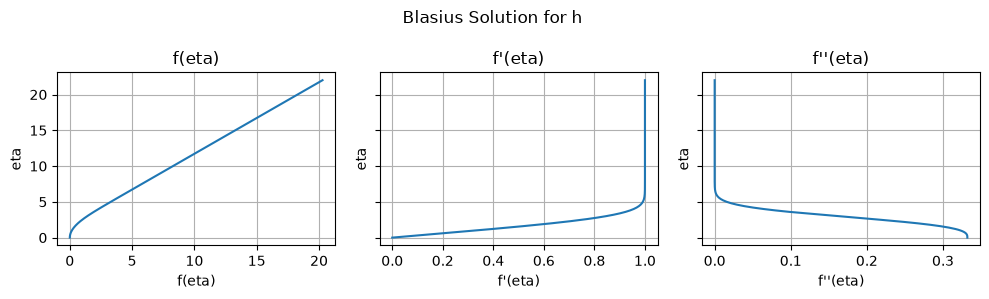

In [56]:
import numpy as np
import matplotlib.pyplot as plt

eta_inf = 22
h = 0.1

# RK3
def first_order(u1, u2, u3):
    Y = np.array([u1, u2, u3])
    G = np.array([[0, 1, 0],[0, 0, 1],[0, 0, -u1/2]])

    Y_d = G @ Y
    return Y_d

def RK3(s,h, eta_inf):
    
    N = int(eta_inf / h)
    Y = np.zeros((N + 1, 3))
    eta = np.linspace(0, eta_inf, N + 1)

    Y[0, 0] = 0
    Y[0, 1] = 0 
    Y[0, 2] = s
    
    for i in range(N):
        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])
        K2 = h * first_order(Y[i, 0] + K1[0]/2, Y[i, 1] + K1[1]/2, Y[i, 2] + K1[2]/2)
        K3 = h * first_order(Y[i, 0] - K1[0] + 2*K2[0], Y[i, 1] - K1[1] + 2*K2[1], Y[i, 2] - K1[2] + 2*K2[2])

        Y[i+1, 0] = Y[i, 0] + (K1[0] + 4*K2[0] + K3[0])/6
        Y[i+1, 1] = Y[i, 1] + (K1[1] + 4*K2[1] + K3[1])/6
        Y[i+1, 2] = Y[i, 2] + (K1[2] + 4*K2[2] + K3[2])/6

    err = Y[-1, 1] - 1

    return eta, Y, err

def error(s, h):
    error = RK3(s, h, eta_inf)[2]
    return error 

def bisection(sl, su, eps, h):
    while (su - sl)/2 > eps:
        s = (su + sl)/2
        if error(s, h) == 0:
            return s 
            
        if error(sl, h)*error(s, h) < 0:
            su = s
        else:
            sl = s
    return s 

sl = 0
su = 1
eps = 1e-20

eta, Y, err1 = RK3(bisection(sl, su, eps, h), h, eta_inf)

print("Shooting Parameter s: ", bisection(sl, su, eps, h))
print("f'(eta): ", Y[-1,1])

fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
ax[0].plot(Y[:, 0], eta)
ax[0].set_xlabel("f(eta)")
ax[0].set_ylabel("eta")
ax[0].set_title("f(eta)")

ax[1].plot(Y[:, 1], eta)
ax[1].set_xlabel("f'(eta)")
ax[1].set_ylabel("eta")
ax[1].set_title("f'(eta)")

ax[2].plot(Y[:, 2], eta)
ax[2].set_xlabel("f''(eta)")
ax[2].set_ylabel("eta")
ax[2].set_title("f''(eta)")

for a in ax:
    a.grid(True)
fig.suptitle(f"Blasius Solution for h ")    
plt.tight_layout()
plt.show()

We see the plots above and they are consistent with the boundary conditions. We also confirm the assumed shooting parameter with the exact solution. Here, we are getting $s =  0.3320565334009135$ which upto 3 digits meets our requirement. 

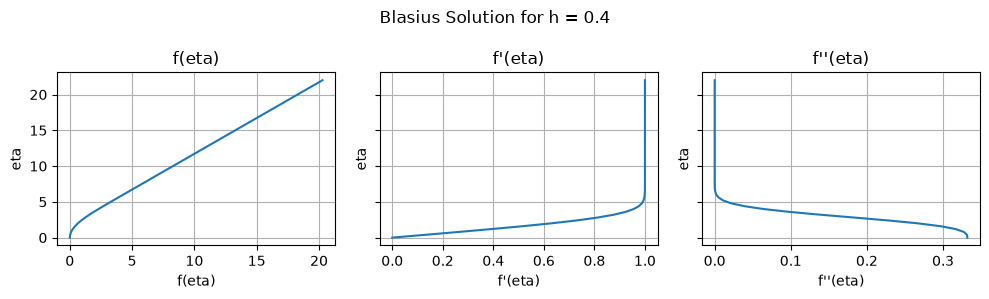

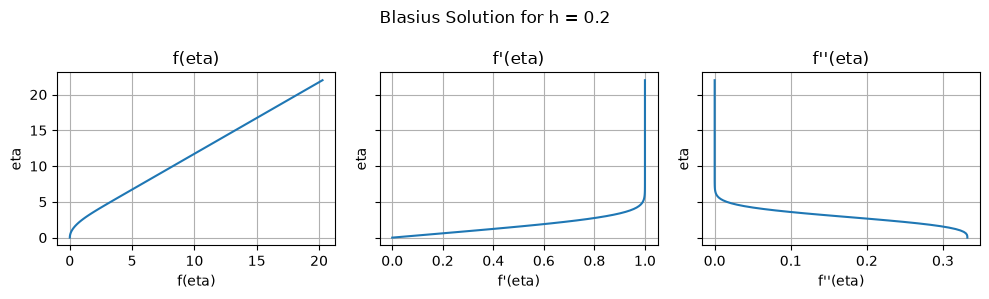

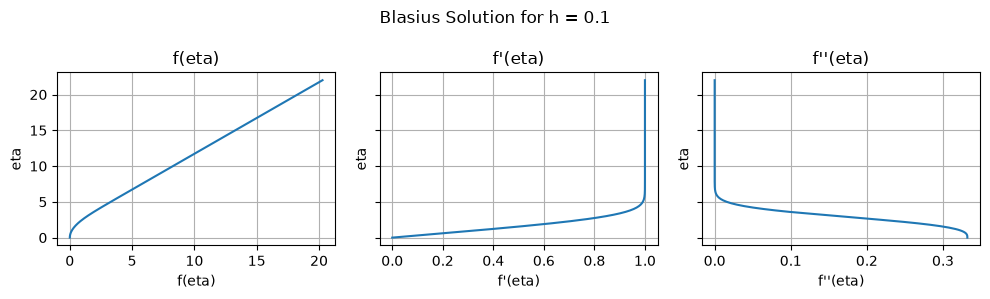

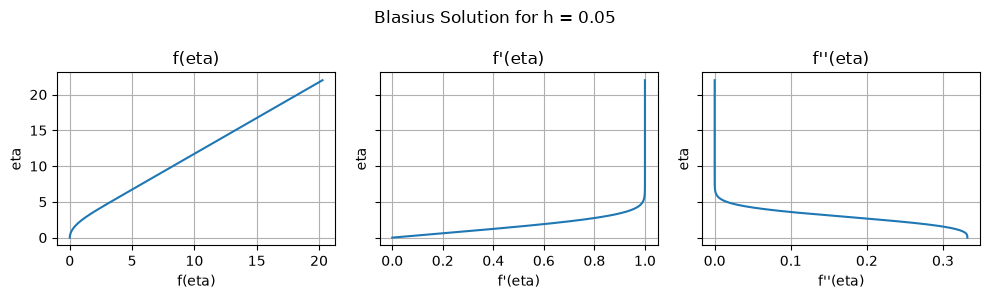

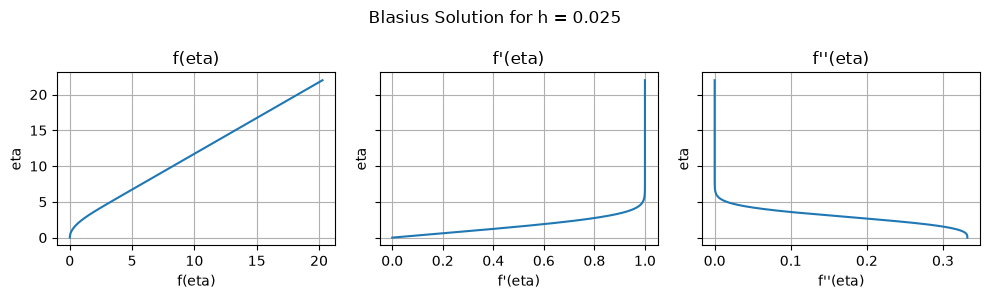

Shooting Values s:  [0.33197714 0.3320496  0.33205653 0.33205725 0.33205733]
Error Values: [8.01922171e-05 7.73869388e-06 8.03761523e-07 8.95936977e-08
 1.04871346e-08]


In [57]:
h_values = [0.4, 0.2, 0.1, 0.05, 0.025]
sl = 0
su = 0.5
eps = 1e-15
s_value = np.zeros(len(h_values))
error_values = np.zeros(len(h_values))

for i, hi in enumerate(h_values):
    s_value[i] = bisection(sl, su, eps, hi)
    eta, Y, err = RK3(s_value[i], hi, eta_inf)
    
    s_exact = 0.3320573362
    error_values[i] = np.abs(s_value[i] - s_exact)
    
    # Plot f, f' and f''
    fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharey=True)

    ax[0].plot(Y[:, 0], eta)
    ax[0].set_xlabel("f(eta)")
    ax[0].set_ylabel("eta")
    ax[0].set_title("f(eta)")
    
    ax[1].plot(Y[:, 1], eta)
    ax[1].set_xlabel("f'(eta)")
    ax[1].set_ylabel("eta")
    ax[1].set_title("f'(eta)")
    
    ax[2].plot(Y[:, 2], eta)
    ax[2].set_xlabel("f''(eta)")
    ax[2].set_ylabel("eta")
    ax[2].set_title("f''(eta)")
    
    fig.suptitle(f"Blasius Solution for h = {hi}")
    
    for a in ax:
        a.grid(True)
    
    plt.tight_layout()
    plt.show()

print('Shooting Values s: ', s_value)
print('Error Values:', error_values)

These are graphs for various time steps: $\Delta\eta = h = 0.4, 0.2, 0.1, 0.05, 0.025$. We confirm the shooting parameter $s$ upto 3 digits which is exactly equal to 0.332. 

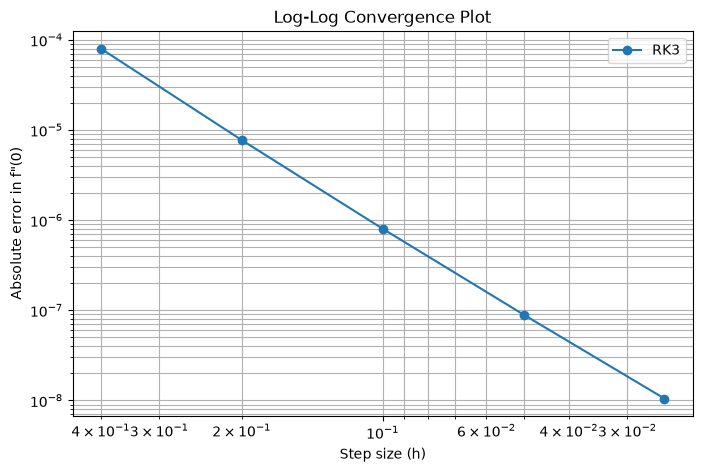

Order of Accuracy:  [3.37330023 3.26725067 3.16529836 3.09477671]


In [58]:
order = np.zeros(len(h_values) - 1)

for i in range(len(h_values) - 1):
    order[i] = np.log(error_values[i]/error_values[i + 1])/np.log(h_values[i]/h_values[i + 1])

plt.figure(figsize=(8,5))
plt.loglog(h_values, error_values, 'o-', label='RK3')
plt.xlabel('Step size (h)')
plt.ylabel('Absolute error in f"(0)')
plt.title('Log-Log Convergence Plot')
plt.grid(True, which='both')
plt.legend()
plt.gca().invert_xaxis()
plt.show()

print("Order of Accuracy: ", order)

In **RK3**, we should expect **thrid order accuracy**, and with the plot plotted above we can see the results, they are $order = [3.37, 3.26, 3.17,  3.22]$. They are close to $p = 3$. 

Below is the **RK4** numerical method executed in the same way as **RK3**. Graphs for $f, f', f'' vs \eta$ are plotted below and order of accuracy is also plotted which is expected to be $O(h^4)$. 

**RK4 Scheme**
$$\begin{aligned}
K_1 &= hF(Y_n)\\
K_2 &= hF\left(Y_n+\frac{K_1}{2}\right)\\
K_3 &= hF\left(Y_n+\frac{K_2}{2}\right)\\
K_4 &= hF(Y_n+K_3)
\end{aligned}$$
updation:
$$
Y_{n+1}=Y_n+\frac{1}{6}(K_1+2K_2+2K_3+K_4)
$$

In [59]:
# RK4
def RK4(s, h, eta_inf):
    
    N = int(round(eta_inf / h))
    h = np.float64(eta_inf / N)
    Y = np.zeros((N + 1, 3), dtype = np.float64)
    eta = np.linspace(0, eta_inf, N + 1, dtype = np.float64)

    Y[0, 0] = 0
    Y[0, 1] = 0 
    Y[0, 2] = s
    
    for i in range(N):
        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])
        K2 = h * first_order(Y[i, 0] + K1[0]/2, Y[i, 1] + K1[1]/2, Y[i, 2] + K1[2]/2)
        K3 = h * first_order(Y[i, 0] + K2[0]/2, Y[i, 1] + K2[1]/2, Y[i, 2] + K2[2]/2)
        K4 = h * first_order(Y[i, 0] + K3[0], Y[i, 1] + K3[1], Y[i, 2] + K3[2])

        Y[i+1, 0] = Y[i, 0] + (K1[0] + 2*K2[0] + 2*K3[0] + K4[0])/6
        Y[i+1, 1] = Y[i, 1] + (K1[1] + 2*K2[1] + 2*K3[1] + K4[1])/6
        Y[i+1, 2] = Y[i, 2] + (K1[2] + 2*K2[2] + 2*K3[2] + K4[2])/6

    err = Y[-1, 1] - 1

    return eta, Y, err

def error1(s, h):
    error = RK4(s, h, eta_inf)[2]
    return error 

def bisection1(sl, su, eps, h):
    sl = np.float64(sl)
    su = np.float64(su)
    
    while (su - sl)/2 > eps:
        s = (su + sl)/2
        if error1(s, h) == 0:
            return s 
            
        if error1(sl, h)*error1(s, h) < 0:
            su = s
        else:
            sl = s
    return s 

Above we define **RK4** method, and below have plotted graphs obtained via RK4. 

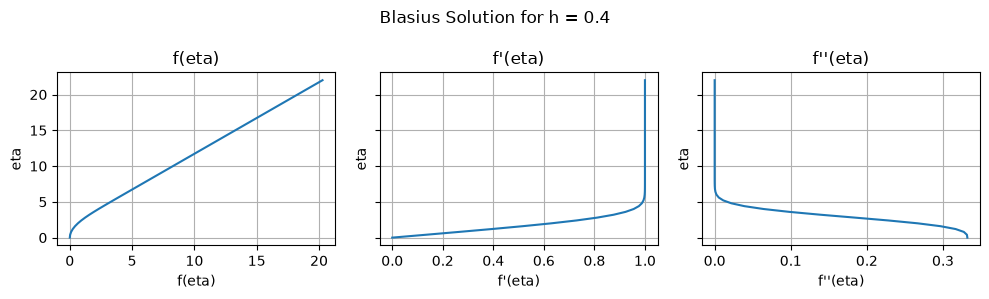

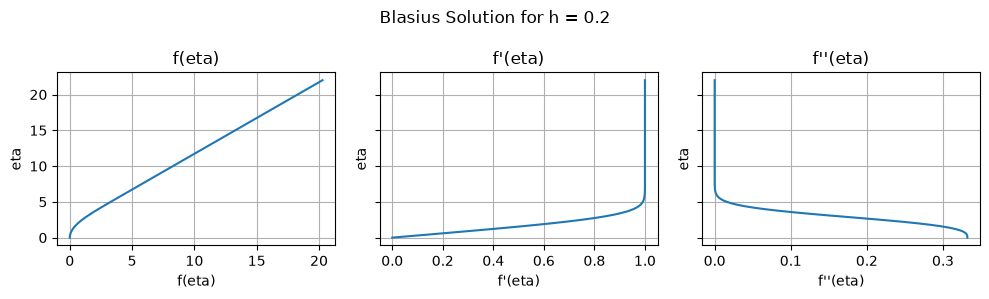

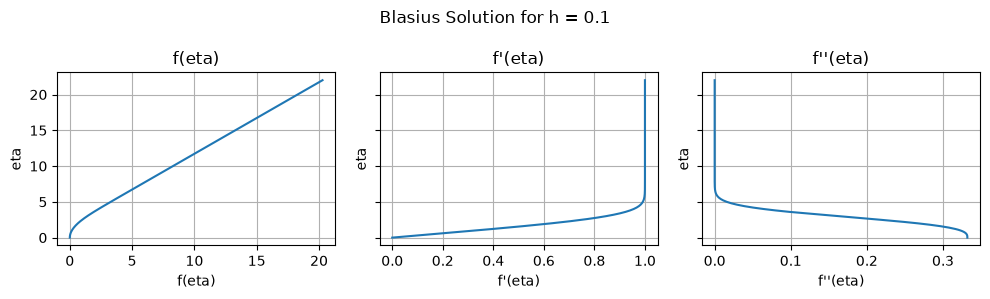

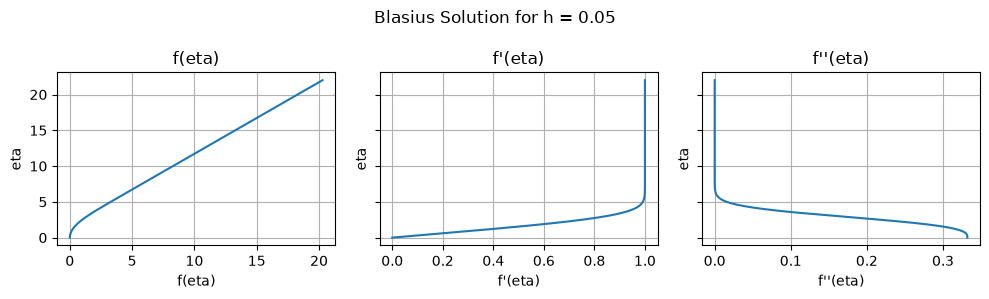

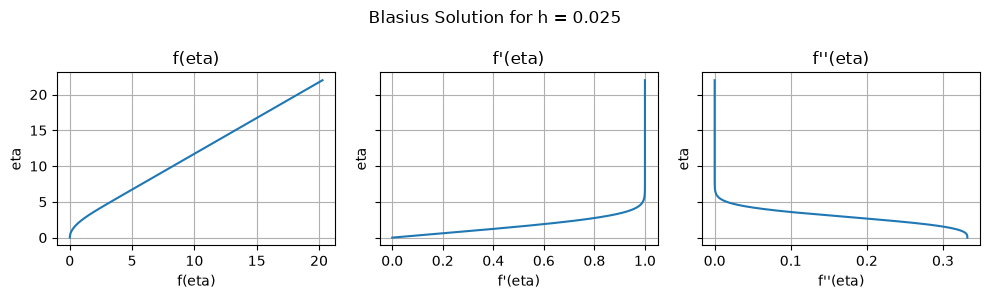

Shooting Values s:  [0.33205884 0.33205746 0.33205734 0.33205734 0.33205734]
Error Values: [1.50088678e-06 1.20221147e-07 8.42018055e-09 5.68643466e-10
 5.06692466e-11]


In [60]:
h_values = [0.4, 0.2, 0.1, 0.05, 0.025]
sl = 0.3
su = 0.4
eps = 1e-15
s_value1 = np.zeros(len(h_values))
error_values1 = np.zeros(len(h_values))

for i, hi in enumerate(h_values):
    s_value1[i] = bisection1(sl, su, eps, hi)
    eta1, Y1, err = RK4(s_value1[i], hi, eta_inf)
    
    s_exact = np.float64(0.3320573362)
    error_values1[i] = np.abs(s_value1[i] - s_exact)
    
    # Plot f, f' and f''
    fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharey=True)

    ax[0].plot(Y1[:, 0], eta1)
    ax[0].set_xlabel("f(eta)")
    ax[0].set_ylabel("eta")
    ax[0].set_title("f(eta)")
    
    ax[1].plot(Y1[:, 1], eta1)
    ax[1].set_xlabel("f'(eta)")
    ax[1].set_ylabel("eta")
    ax[1].set_title("f'(eta)")
    
    ax[2].plot(Y1[:, 2], eta1)
    ax[2].set_xlabel("f''(eta)")
    ax[2].set_ylabel("eta")
    ax[2].set_title("f''(eta)")
    
    fig.suptitle(f"Blasius Solution for h = {hi}")
    
    for a in ax:
        a.grid(True)
    
    plt.tight_layout()
    plt.show()

print('Shooting Values s: ', s_value1)
print('Error Values:', error_values1)

These are graphs for various time steps: $\Delta\eta = h = 0.4, 0.2, 0.1, 0.05, 0.025$. We confirm the shooting parameter $s$ upto 3 digits which is exactly equal to 0.332. 

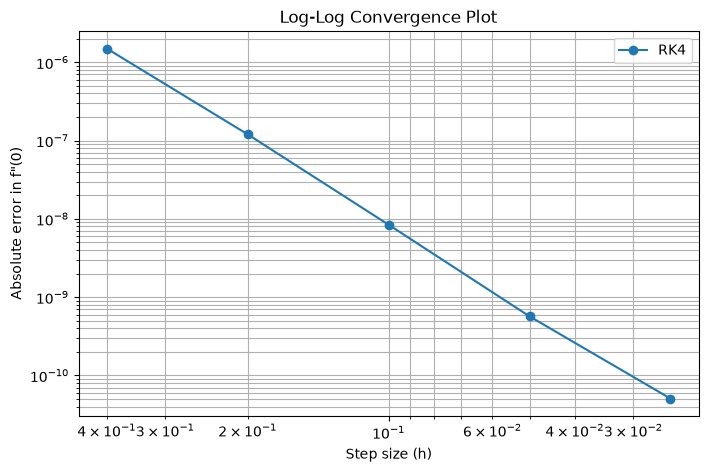

Order of Accuracy:  [3.64205256 3.83569571 3.88825488 3.4883421 ]


In [61]:
order = np.zeros(len(h_values) - 1)

for i in range(len(h_values) - 1):
    order[i] = np.log(error_values1[i]/error_values1[i + 1])/np.log(h_values[i]/h_values[i + 1])

plt.figure(figsize=(8,5))
plt.loglog(h_values, error_values1, 'o-', label='RK4')
plt.xlabel('Step size (h)')
plt.ylabel('Absolute error in f"(0)')
plt.title('Log-Log Convergence Plot')
plt.grid(True, which='both')
plt.legend()
plt.gca().invert_xaxis()
plt.show()

print("Order of Accuracy: ", order)

In **RK4**, we should expect **fourth order accuracy**, and with the plot plotted above we can see the results, they are $order = [3.64, 3.835, 3.888,  3.488]$. The middle 2 are close to $p = 4$. 

In [63]:
print(Y1.dtype)
print(np.finfo(Y1.dtype))

float64
Machine parameters for float64
---------------------------------------------------------------
precision = 15   resolution = 1e-15
machep = -52   eps =        2.220446049250313e-16
negep =  -53   epsneg =     1.1102230246251565e-16
minexp = -1022   tiny =       2.2250738585072014e-308
maxexp = 1024   max =        1.7976931348623157e+308
nexp =   11   min =        -max
smallest_normal = 2.2250738585072014e-308   smallest_subnormal = 5e-324
---------------------------------------------------------------

